In [1]:
from pathlib import Path
import pandas as pd

DATASET = Path("../dataset")  

NOMBRES = ["brokers", "traders", "accounts", "instruments", "market_prices", "fills"]
t = {nombre: pd.read_csv(DATASET / f"{nombre}.csv") for nombre in NOMBRES}

for nombre, df in t.items():
    print(f"{nombre:15s} {df.shape}")

t["fills"].dtypes

brokers         (3, 5)
traders         (48, 8)
accounts        (54, 9)
instruments     (8, 8)
market_prices   (8, 3)
fills           (5146, 10)


id                       str
account_id               str
instrument_symbol        str
side                     str
quantity               int64
price                float64
filled_at                str
order_id                 str
liquidity                str
commission_usd       float64
dtype: object

In [2]:
COLUMNAS_FECHA = {
    "brokers": ["created_at"],
    "traders": ["created_at"],
    "accounts": ["created_at"],
    "market_prices": ["as_of"],
    "fills": ["filled_at"],
}
for nombre, cols in COLUMNAS_FECHA.items():
    for col in cols:
        t[nombre][col] = pd.to_datetime(t[nombre][col], utc=True)

CUT = pd.Timestamp("2026-08-25T14:30:00Z")   # "ahora", según el README

fills = t["fills"]
print(fills["filled_at"].dtype)
print("primer fill:", fills["filled_at"].min())
print("último fill:", fills["filled_at"].max())
print("fills después del corte:", (fills["filled_at"] > CUT).sum())

datetime64[us, UTC]
primer fill: 2026-08-10 10:34:12+00:00
último fill: 2026-08-25 14:19:39+00:00
fills después del corte: 0


In [3]:
f, a = t["fills"], t["accounts"]

# 1. Llaves únicas: cada id aparece una sola vez
assert f["id"].is_unique, "fills.id duplicado"
assert a["id"].is_unique, "accounts.id duplicado"

# 2. Llaves foráneas: todo lo que se referencia existe
assert f["account_id"].isin(a["id"]).all(), "fill con cuenta inexistente"
assert f["instrument_symbol"].isin(t["instruments"]["symbol"]).all(), "símbolo desconocido"
assert a["trader_id"].isin(t["traders"]["id"]).all(), "cuenta con trader inexistente"

# 3. Dominios: valores dentro de lo esperado
assert f.notna().all().all(), "hay nulos en fills"
assert f["side"].isin(["BUY", "SELL"]).all()
assert (f["quantity"] > 0).all() and (f["price"] > 0).all()

# 4. Una orden = una cuenta, un símbolo, un lado
por_orden = f.groupby("order_id")[["account_id", "instrument_symbol", "side"]].nunique()
assert (por_orden == 1).all().all(), "order_id mezcla cuentas, símbolos o lados"

print("Esquema OK")

Esquema OK


In [4]:
hora_ct = fills["filled_at"].dt.tz_convert("America/Chicago").dt.tz_localize(None)
fills["filled_at_ct"] = hora_ct
fills["session_date"] = (hora_ct + pd.Timedelta(hours=7)).dt.normalize()

# Validaciones: el mercado cierra de 16:00 a 17:00 CT y no hay sesiones en fin de semana
assert (hora_ct.dt.hour != 16).all(), "fill durante la pausa diaria"
assert (fills["session_date"].dt.dayofweek < 5).all(), "sesión en fin de semana"

print(fills["session_date"].value_counts().sort_index())

# ¿Cuántos fills caerían en el día equivocado si agrupáramos por fecha UTC?
fecha_utc = fills["filled_at"].dt.tz_localize(None).dt.normalize()
distintos = fills[fecha_utc != fills["session_date"]]
print(len(distintos), "fills con fecha UTC distinta a su sesión")
distintos[["account_id", "instrument_symbol", "filled_at", "filled_at_ct", "session_date"]]

session_date
2026-08-10    309
2026-08-11    365
2026-08-12    426
2026-08-13    452
2026-08-14    446
2026-08-17    422
2026-08-18    441
2026-08-19    424
2026-08-20    454
2026-08-21    430
2026-08-24    480
2026-08-25    497
Name: count, dtype: int64
10 fills con fecha UTC distinta a su sesión


C:\Users\juan esteban\AppData\Local\Temp\ipykernel_5264\797164082.py:7: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  assert (fills["session_date"].dt.dayofweek < 5).all(), "sesión en fin de semana"


,account_id,instrument_symbol,filled_at,filled_at_ct,session_date
4649,ACC-2023,MES,2026-08-24 22:02:45+00:00,2026-08-24 17:02:45,2026-08-25
4650,ACC-2024,MNQ,2026-08-24 22:05:42+00:00,2026-08-24 17:05:42,2026-08-25
4651,ACC-2023,MES,2026-08-24 22:14:45+00:00,2026-08-24 17:14:45,2026-08-25
4652,ACC-2024,MNQ,2026-08-24 22:15:42+00:00,2026-08-24 17:15:42,2026-08-25
4653,ACC-2024,MNQ,2026-08-24 22:23:21+00:00,2026-08-24 17:23:21,2026-08-25
4654,ACC-2024,MNQ,2026-08-24 22:26:21+00:00,2026-08-24 17:26:21,2026-08-25
4655,ACC-2023,MES,2026-08-24 22:46:34+00:00,2026-08-24 17:46:34,2026-08-25
4656,ACC-2023,MES,2026-08-24 23:02:34+00:00,2026-08-24 18:02:34,2026-08-25
4657,ACC-2023,MES,2026-08-24 23:04:23+00:00,2026-08-24 18:04:23,2026-08-25
4658,ACC-2023,MES,2026-08-24 23:06:23+00:00,2026-08-24 18:06:23,2026-08-25


In [5]:
import numpy as np

# Órdenes vs. fills
fills_por_orden = fills.groupby("order_id").size()
print(f"{len(fills)} fills, {fills_por_orden.size} órdenes, "
      f"{(fills_por_orden > 1).sum()} órdenes con fills parciales")

# Point value: cuántos USD vale 1 punto de cada instrumento
point_value = t["instruments"].set_index("symbol")["point_value_usd"]
fills["point_value_usd"] = fills["instrument_symbol"].map(point_value)

# Cantidad con signo: compra suma posición, venta resta
fills["signed_qty"] = np.where(fills["side"] == "BUY", 1, -1) * fills["quantity"]

t["instruments"][["symbol", "description", "point_value_usd"]]

5146 fills, 4886 órdenes, 260 órdenes con fills parciales


,symbol,description,point_value_usd
0,ES,E-mini S&P 500,50
1,MES,Micro E-mini S&P 500,5
2,NQ,E-mini Nasdaq-100,20
3,MNQ,Micro E-mini Nasdaq-100,2
4,CL,Crude Oil,1000
5,MCL,Micro Crude Oil,100
6,GC,Gold,100
7,6E,Euro FX,125000


In [6]:
fills = fills.sort_values(["filled_at", "id"]).reset_index(drop=True)

estado = {}   # (cuenta, símbolo) -> (posición, precio_promedio)
pos_despues, pnl_realizado = [], []

for cuenta, sym, q, px, pv in fills[["account_id", "instrument_symbol", "signed_qty",
                                     "price", "point_value_usd"]].itertuples(index=False):
    pos, prom = estado.get((cuenta, sym), (0, 0.0))
    pnl = 0.0
    if pos == 0 or np.sign(pos) == np.sign(q):            # abre o aumenta
        prom = (prom * abs(pos) + px * abs(q)) / (abs(pos) + abs(q))
        pos += q
    else:                                                 # reduce, cierra o invierte
        cerrada = min(abs(q), abs(pos))
        pnl = cerrada * (px - prom) * np.sign(pos) * pv
        pos += q
        if pos == 0:
            prom = 0.0
        elif np.sign(pos) == np.sign(q):                  # se invirtió
            prom = px
    estado[(cuenta, sym)] = (pos, prom)
    pos_despues.append(pos)
    pnl_realizado.append(pnl)

fills["position_after"] = pos_despues
fills["realized_gross_usd"] = pnl_realizado

In [7]:
llaves = ["account_id", "instrument_symbol"]
caja = (-fills["signed_qty"] * fills["price"] * fills["point_value_usd"]).groupby(
    [fills[k] for k in llaves]).sum()
realizado = fills.groupby(llaves)["realized_gross_usd"].sum()
plana = fills.groupby(llaves)["position_after"].last() == 0

dif = (caja[plana] - realizado[plana]).abs().max()
print(f"Diferencia máxima: {dif:.2e} USD")
assert dif < 1e-6
print("PnL bruto realizado total:", round(fills["realized_gross_usd"].sum(), 2))

Diferencia máxima: 5.00e-10 USD
PnL bruto realizado total: -43209.5


In [8]:
# Posiciones abiertas al corte
marks = t["market_prices"].set_index("symbol")["mark_price"]
abiertas = pd.DataFrame(
    [(c, s, pos, prom) for (c, s), (pos, prom) in estado.items() if pos != 0],
    columns=["account_id", "instrument_symbol", "position", "avg_price"])
abiertas["mark_price"] = abiertas["instrument_symbol"].map(marks)
abiertas["point_value_usd"] = abiertas["instrument_symbol"].map(point_value)
abiertas["unrealized_usd"] = ((abiertas["mark_price"] - abiertas["avg_price"])
                              * abiertas["position"] * abiertas["point_value_usd"])
ultima_sesion = fills.groupby(["account_id", "instrument_symbol"])["session_date"].max()
abiertas["session_date"] = abiertas.set_index(["account_id", "instrument_symbol"]).index.map(ultima_sesion)
print(abiertas)

# ¿Alguna sesión histórica cerró con posición abierta?
fin = fills.groupby(["account_id", "instrument_symbol", "session_date"])["position_after"].last()
print("Posiciones overnight:", (fin[fin.index.get_level_values("session_date") < "2026-08-25"] != 0).sum())

# Tabla final: una fila por (cuenta, sesión)
sesiones = fills.groupby(["account_id", "session_date"]).agg(
    n_fills=("id", "size"),
    n_orders=("order_id", "nunique"),
    contracts=("quantity", "sum"),
    max_abs_position=("position_after", lambda s: s.abs().max()),
    realized_gross_usd=("realized_gross_usd", "sum"),
    commissions_usd=("commission_usd", "sum"),
).reset_index()

no_real = abiertas.groupby(["account_id", "session_date"])["unrealized_usd"].sum()
sesiones["unrealized_usd"] = sesiones.set_index(["account_id", "session_date"]).index.map(no_real)
sesiones["unrealized_usd"] = sesiones["unrealized_usd"].fillna(0.0)
sesiones["net_pnl_usd"] = (sesiones["realized_gross_usd"] - sesiones["commissions_usd"]
                           + sesiones["unrealized_usd"])

print(sesiones.shape)
sesiones[["realized_gross_usd", "commissions_usd", "unrealized_usd", "net_pnl_usd"]].sum().round(0)

  account_id instrument_symbol  position  avg_price  mark_price  \
0   ACC-2017               MES         6    5640.00     5642.25   
1   ACC-2034               MES         1    5640.75     5642.25   
2   ACC-2050               MES         1    5640.75     5642.25   
3   ACC-2054               MNQ         2   19805.50    19845.50   
4   ACC-2026                CL        -3      73.40       74.18   
5   ACC-2028               MNQ         1   19833.50    19845.50   
6   ACC-2044               MES         2    5640.75     5642.25   
7   ACC-2039               MES         2    5640.75     5642.25   

   point_value_usd  unrealized_usd session_date  
0                5            67.5   2026-08-25  
1                5             7.5   2026-08-25  
2                5             7.5   2026-08-25  
3                2           160.0   2026-08-25  
4             1000         -2340.0   2026-08-25  
5                2            24.0   2026-08-25  
6                5            15.0   2026-08-2

realized_gross_usd   -43209.0
commissions_usd       22099.0
unrealized_usd        -2044.0
net_pnl_usd          -67352.0
dtype: float64

In [9]:
a = t["accounts"]
hallazgos = []
def anota(check, entidad, detalle):
    hallazgos.append({"check": check, "entidad": entidad, "detalle": detalle})

# 1. Sesión de hoy incompleta
anota("sesion_parcial", "2026-08-25", "Al corte (09:30 CT) lleva 16.5 de 23 horas")

# 2. Cuentas no activas, demo o con balance cero
for r in a.itertuples():
    n = (fills["account_id"] == r.id).sum()
    if r.status != "active" and n > 0:
        anota("cuenta_no_activa_con_fills", f"{r.id} ({r.trader_id})", f"status={r.status}, {n} fills")
    if r.account_type == "demo":
        anota("cuenta_demo", f"{r.id} ({r.trader_id})", f"{n} fills")
    if r.balance <= 0 and n > 0:
        anota("balance_cero_con_fills", f"{r.id} ({r.trader_id})", f"balance={r.balance}, {n} fills")

# 3. Historial corto: pocas sesiones para estimar el "normal" del trader
n_ses = sesiones.groupby("account_id")["session_date"].nunique()
for cuenta, n in n_ses[n_ses <= 3].items():
    anota("historial_corto", cuenta, f"solo {n} sesión(es)")

# 4. Traders con varias cuentas y nombres repetidos
cuentas_por_trader = a.groupby("trader_id")["id"].agg(list)
for trader, cuentas in cuentas_por_trader[cuentas_por_trader.str.len() > 1].items():
    anota("trader_multicuenta", trader, ", ".join(cuentas))
tr = t["traders"]
nombre = tr["first_name"] + " " + tr["last_name"]
for nom, ids in tr.groupby(nombre)["id"].agg(list).items():
    if len(ids) > 1:
        anota("nombre_duplicado", ", ".join(ids), nom)

# 5. Posición máxima por encima del límite de la cuenta
max_pos = fills.groupby("account_id")["position_after"].apply(lambda s: s.abs().max())
limite = a.set_index("id")["max_position_size"]
for cuenta in max_pos.index[max_pos > limite.reindex(max_pos.index)]:
    anota("excede_max_position", cuenta, f"máx {max_pos[cuenta]} vs límite {limite[cuenta]}")

# 6. Instrumentos casi sin datos
for sym, n in fills["instrument_symbol"].value_counts().loc[lambda s: s < 30].items():
    anota("instrumento_poco_operado", sym, f"solo {n} fills")

# 7. Precios a más de 2% de la mediana de su instrumento en esa sesión
mediana = fills.groupby(["instrument_symbol", "session_date"])["price"].transform("median")
raros = fills[(fills["price"] / mediana - 1).abs() > 0.02]
for r in raros.itertuples():
    anota("precio_atipico", f"{r.id} {r.account_id}", f"{r.instrument_symbol} @ {r.price}")

anomalias = pd.DataFrame(hallazgos)
print(anomalias["check"].value_counts())
anomalias

check
precio_atipico                9
trader_multicuenta            5
historial_corto               4
cuenta_no_activa_con_fills    2
excede_max_position           2
sesion_parcial                1
balance_cero_con_fills        1
cuenta_demo                   1
nombre_duplicado              1
instrumento_poco_operado      1
Name: count, dtype: int64


,check,entidad,detalle
0,sesion_parcial,2026-08-25,Al corte (09:30 CT) lleva 16.5 de 23 horas
1,balance_cero_con_fills,ACC-2028 (T-025),"balance=0.0, 3 fills"
2,cuenta_demo,ACC-2047 (T-043),0 fills
3,cuenta_no_activa_con_fills,ACC-2053 (T-040),"status=closed, 20 fills"
4,cuenta_no_activa_con_fills,ACC-2054 (T-041),"status=restricted, 3 fills"
5,historial_corto,ACC-2027,solo 1 sesión(es)
6,historial_corto,ACC-2028,solo 1 sesión(es)
7,historial_corto,ACC-2029,solo 2 sesión(es)
8,historial_corto,ACC-2054,solo 2 sesión(es)
9,trader_multicuenta,T-018,"ACC-2018, ACC-2019, ACC-2020"


In [10]:
cuentas = a[["id", "trader_id", "account_type", "status"]].rename(columns={"id": "account_id"})
sesiones = sesiones.merge(cuentas, on="account_id", how="left", validate="many_to_one")
assert sesiones["trader_id"].notna().all()

real = sesiones[sesiones["account_type"] != "demo"]      # la demo no es dinero real
por_trader = real.groupby(["trader_id", "session_date"]).agg(
    n_accounts=("account_id", "nunique"),
    n_orders=("n_orders", "sum"),
    contracts=("contracts", "sum"),
    net_pnl_usd=("net_pnl_usd", "sum"),
).reset_index()

print(por_trader.shape)
print("Sesiones por trader:")
print(por_trader.groupby("trader_id")["session_date"].nunique().value_counts().sort_index())
por_trader[por_trader["n_accounts"] > 1]["trader_id"].value_counts()

(516, 6)
Sesiones por trader:
session_date
1      2
2      1
9      1
10     9
11     7
12    28
Name: count, dtype: int64


trader_id
T-019    10
T-018     9
T-040     5
T-041     2
Name: count, dtype: int64

In [11]:
MIN_HIST = 5   # con menos de 5 sesiones previas, su "normal" no es confiable

def linea_base(g):
    g = g.sort_values("session_date").copy()
    med, disp, med_c, peor, n = [], [], [], [], []
    for i in range(len(g)):
        h = g.iloc[:i]                      # SOLO sesiones anteriores a la i
        n.append(len(h))
        if len(h) == 0:
            med.append(np.nan); disp.append(np.nan); med_c.append(np.nan); peor.append(np.nan)
            continue
        m = h["net_pnl_usd"].median()
        med.append(m)
        disp.append(1.4826 * (h["net_pnl_usd"] - m).abs().median())
        med_c.append(h["contracts"].median())
        peor.append(h["net_pnl_usd"].min())
    return g.assign(n_hist=n, base_pnl=med, base_disp=disp, base_contracts=med_c, peor_previa=peor)

por_trader = pd.concat([linea_base(g) for _, g in por_trader.groupby("trader_id")], ignore_index=True)
por_trader.loc[por_trader["n_hist"] < MIN_HIST, ["base_pnl", "base_disp"]] = np.nan

print(por_trader.shape, "filas con línea base:", por_trader["base_pnl"].notna().sum())
por_trader[por_trader["trader_id"] == "T-020"][["session_date", "contracts", "net_pnl_usd", "n_hist",
                                                 "base_pnl", "base_disp", "base_contracts", "peor_previa"]].round(1)

(516, 11) filas con línea base: 287


C:\Users\juan esteban\AppData\Local\Temp\ipykernel_5264\1404039010.py:24: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  "base_pnl", "base_disp", "base_contracts", "peor_previa"]].round(1)


,session_date,contracts,net_pnl_usd,n_hist,base_pnl,base_disp,base_contracts,peor_previa
223,2026-08-10,28,-137.1,0,NaN,NaN,NaN,NaN
224,2026-08-11,32,-1267.4,1,NaN,NaN,28.0,-137.1
225,2026-08-12,22,-44.2,2,NaN,NaN,30.0,-1267.4
226,2026-08-13,28,110.4,3,NaN,NaN,28.0,-1267.4
227,2026-08-14,34,17.4,4,NaN,NaN,28.0,-1267.4
228,2026-08-17,26,678.0,5,-44.2,137.8,28.0,-1267.4
229,2026-08-18,20,-387.8,6,-13.4,183.5,28.0,-1267.4
230,2026-08-19,30,342.8,7,-44.2,229.1,28.0,-1267.4
231,2026-08-20,28,285.4,8,-13.4,355.7,28.0,-1267.4
232,2026-08-21,20,-769.0,9,17.4,397.3,28.0,-1267.4


In [12]:
import re

HOY = pd.Timestamp("2026-08-25")
hoy = por_trader[por_trader["session_date"] == HOY].copy()

hoy["z"] = (hoy["net_pnl_usd"] - hoy["base_pnl"]) / hoy["base_disp"].clip(lower=50)
hoy["tamano_vs_normal"] = hoy["contracts"] / hoy["base_contracts"]
hoy["peor_que_su_peor"] = hoy["net_pnl_usd"] < hoy["peor_previa"]

con_hist = hoy[hoy["base_pnl"].notna() & (hoy["net_pnl_usd"] < 0)]
top10 = con_hist.nsmallest(10, "z")

# Pegar las anomalías del paso 8 a cada trader (la entidad puede ser una cuenta o un trader)
cuenta_a_trader = a.set_index("id")["trader_id"]
def traders_de(entidad):
    ids = set(re.findall(r"T-\d{3}", entidad))
    ids |= {cuenta_a_trader[c] for c in re.findall(r"ACC-\d{4}", entidad)}
    return ids
notas = {}
for r in anomalias.itertuples():
    for tid in traders_de(r.entidad):
        notas.setdefault(tid, []).append(r.check)
top10["notas"] = top10["trader_id"].map(lambda tid: ", ".join(sorted(set(notas.get(tid, [])))))

top10.insert(0, "rank", range(1, 11))
cols = ["rank", "trader_id", "n_accounts", "contracts", "base_contracts", "tamano_vs_normal",
        "net_pnl_usd", "base_pnl", "base_disp", "peor_previa", "peor_que_su_peor", "z", "notas"]
print(top10[cols].round(2).to_string(index=False))

sin_hist = hoy[hoy["base_pnl"].isna()]
sin_hist[["trader_id", "n_hist", "contracts", "net_pnl_usd"]]

 rank trader_id  n_accounts  contracts  base_contracts  tamano_vs_normal  net_pnl_usd  base_pnl  base_disp  peor_previa  peor_que_su_peor      z              notas
    1     T-011           1         14            14.0              1.00      -758.55     15.70      59.23      -246.10              True -13.07                   
    2     T-018           3         24            28.0              0.86     -1516.80   -130.77     125.32      -350.85              True -11.06 trader_multicuenta
    3     T-019           2         26            24.0              1.08     -1559.20    129.30     202.52      -494.50              True  -8.34 trader_multicuenta
    4     T-009           1         12            10.0              1.20      -669.95    -30.60      86.88      -252.30              True  -7.36                   
    5     T-020           1         52            28.0              1.86     -2397.65     17.45     397.26     -1267.40              True  -6.08                   
    6     T-012 

,trader_id,n_hist,contracts,net_pnl_usd
271,T-024,0,38,-1579.60
272,T-025,0,5,-72.00
274,T-026,1,6,-127.95


In [13]:
salida = Path("../outputs"); salida.mkdir(exist_ok=True)
top10[cols].to_csv(salida / "top10.csv", index=False)
sin_hist.to_csv(salida / "sin_historial.csv", index=False)
anomalias.to_csv(salida / "anomalias.csv", index=False)
sesiones.to_csv(salida / "sesiones_cuenta.csv", index=False)

In [14]:
t020 = fills[fills["account_id"].isin(a.loc[a["trader_id"] == "T-020", "id"])].copy()
t020["hora_ct"] = t020["filled_at"].dt.tz_convert("America/Chicago").dt.hour
t020.groupby("session_date").agg(
    ordenes=("order_id", "nunique"), contratos=("quantity", "sum"),
    pos_max=("position_after", lambda s: s.abs().max()),
    horas_ct=("hora_ct", lambda s: sorted(set(s))),
    pnl_bruto=("realized_gross_usd", "sum"))

,ordenes,contratos,pos_max,horas_ct,pnl_bruto
session_date,,,,,
2026-08-10,6,28,5,"[5, 10, 14]",-117.50
2026-08-11,6,32,6,"[5, 10, 14]",-1245.00
2026-08-12,6,22,5,"[5, 6, 10, 14]",-28.75
2026-08-13,6,28,6,"[5, 6, 10, 14]",130.00
2026-08-14,6,34,6,"[5, 10, 14]",41.25
2026-08-17,6,26,5,"[5, 10, 14, 15]",696.25
2026-08-18,6,20,4,"[5, 10, 14, 15]",-373.75
2026-08-19,6,30,6,"[5, 6, 10, 14, 15]",363.75
2026-08-20,6,28,6,"[5, 6, 10, 14, 15]",305.00


Matplotlib is building the font cache; this may take a moment.


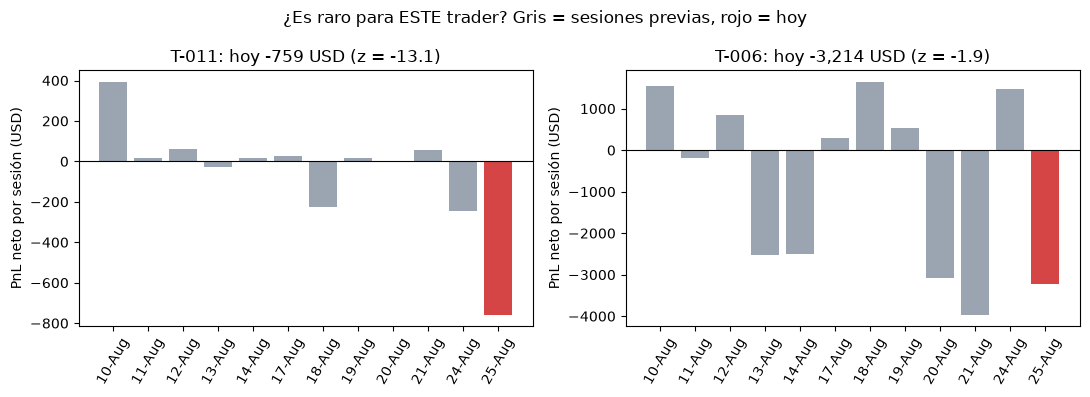

In [15]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, tid in zip(axes, ["T-011", "T-006"]):
    d = por_trader[por_trader["trader_id"] == tid]
    previas, de_hoy = d[d["session_date"] < HOY], d[d["session_date"] == HOY]
    ax.bar(previas["session_date"].dt.strftime("%d-%b"), previas["net_pnl_usd"], color="#9aa5b1")
    ax.bar(de_hoy["session_date"].dt.strftime("%d-%b"), de_hoy["net_pnl_usd"], color="#d64545")
    ax.axhline(0, color="black", lw=0.8)
    z = hoy.loc[hoy["trader_id"] == tid, "z"].iloc[0]
    ax.set_title(f"{tid}: hoy {de_hoy['net_pnl_usd'].iloc[0]:,.0f} USD (z = {z:.1f})")
    ax.tick_params(axis="x", rotation=60)
    ax.set_ylabel("PnL neto por sesión (USD)")
fig.suptitle("¿Es raro para ESTE trader? Gris = sesiones previas, rojo = hoy")
fig.tight_layout()
fig.savefig("../outputs/slide_t011_vs_t006.png", dpi=150)